In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar tu paquete de src/ sin instalarlo
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))


# 02 · EDA — qué hay realmente en mis datos (OnTrack)

> Guía completa: `material-del-curso/kit/guia-eda-y-preprocesamiento.md`. Especificación: `especificaciones/02-eda.md`.

El EDA **no es hacer gráficos**: es descubrir qué decisiones hay que tomar antes de modelar. Este
notebook termina con una **tabla de 10 decisiones**, cada una con una cifra y un motivo.
Los hallazgos y la tabla también están en `reports/01_eda.md`.

**Preguntas guía:** (1) unidad de análisis · (2) objetivo · (3) suciedad · (4) qué debería ser estable ·
(5) sospecha de fuga.

## 0. Cargar los datos

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from olistbr.config import RAW_DIR  # ruta de data/raw/ (solo lectura), definida en src/olistbr/config.py
leer = lambda nombre, **kw: pd.read_csv(RAW_DIR / f"{nombre}.csv", **kw)

orders    = leer("olist_orders_dataset")
customers = leer("olist_customers_dataset")
items     = leer("olist_order_items_dataset")
products  = leer("olist_products_dataset")
sellers   = leer("olist_sellers_dataset")
payments  = leer("olist_order_payments_dataset")
geo       = leer("olist_geolocation_dataset")
traduccion = leer("product_category_name_translation")

# Datos personales: los comentarios de las reseñas son texto libre. Se miden y se descartan al cargar.
reseñas_texto = leer("olist_order_reviews_dataset", usecols=["review_comment_title", "review_comment_message"])
print("reseñas con título:", f"{reseñas_texto.review_comment_title.notna().mean():.1%}",
      "| con mensaje:", f"{reseñas_texto.review_comment_message.notna().mean():.1%}", "-> se descartan")
del reseñas_texto
reviews = leer("olist_order_reviews_dataset", usecols=["review_id", "order_id", "review_score"])

FECHAS = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
          "order_delivered_customer_date", "order_estimated_delivery_date"]
tipos_csv = orders[FECHAS].dtypes.astype(str)          # en el CSV las fechas llegan como texto
orders[FECHAS] = orders[FECHAS].apply(pd.to_datetime)

# Una fila por pedido, con la persona (customer_unique_id) y el estado del cliente
df = orders.merge(customers, on="customer_id", how="left")
DIA = 86400
df["dias_entrega"]    = (df.order_delivered_customer_date - df.order_purchase_timestamp).dt.total_seconds() / DIA
df["dias_prometidos"] = (df.order_estimated_delivery_date - df.order_purchase_timestamp).dt.total_seconds() / DIA

ID_COL = "order_id"        # identifica un pedido (la partición se hará por customer_unique_id)
TARGET = "dias_entrega"    # días entre la compra y la entrega al cliente (se construye)

print(f"orders: {df.shape[0]:,} filas x {orders.shape[1]} columnas originales (+ cliente y objetivo)")
for nombre, t in {"customers": customers, "order_items": items, "products": products, "sellers": sellers,
                  "payments": payments, "reviews": reviews, "geolocation": geo}.items():
    print(f"{nombre:12s} {t.shape[0]:>9,} x {t.shape[1]}")

reseñas con título: 11.7% | con mensaje: 41.3% -> se descartan
orders: 99,441 filas x 8 columnas originales (+ cliente y objetivo)
customers       99,441 x 5
order_items    112,650 x 7
products        32,951 x 9
sellers          3,095 x 4
payments       103,886 x 5
reviews         99,224 x 3
geolocation  1,000,163 x 5


## 1. ¿Cuál es la unidad de análisis? ¿Qué representa una fila?

*Pregunta:* ¿una fila es un cliente, una transacción, un cliente en un mes...? ¿Alguna entidad
aparece en **varias filas**? De eso depende cómo se parte el dato.

In [3]:
print("pedidos:", len(df), "| order_id repetidos:", df[ID_COL].duplicated().sum())

por_persona = df.groupby("customer_unique_id").size()
print("\npersonas distintas:", por_persona.size, "| con más de un pedido:", (por_persona > 1).sum(), "| máximo:", por_persona.max())
print("pedidos por persona:\n", por_persona.value_counts().sort_index().head(6).to_string())

por_pedido = items.groupby("order_id").agg(n_items=("order_item_id", "size"), n_vendedores=("seller_id", "nunique"))
print("\npedidos con ítems:", len(por_pedido), "| con más de un ítem:", (por_pedido.n_items > 1).sum(),
      "| con más de un vendedor:", (por_pedido.n_vendedores > 1).sum())
print("pedidos sin ítems:", (~df.order_id.isin(items.order_id)).sum())

pedidos: 99441 | order_id repetidos: 0

personas distintas: 96096 | con más de un pedido: 2997 | máximo: 17
pedidos por persona:
 1    93099
2     2745
3      203
4       30
5        8
6        6



pedidos con ítems: 98666 | con más de un ítem: 9803 | con más de un vendedor: 1278


pedidos sin ítems: 775


**Mi respuesta (una frase):** una fila de `orders` es un pedido de un cliente. No se repite (0 `order_id` duplicados), pero **la persona sí se repite**: los 99.441 `customer_id` son 96.096 personas (`customer_unique_id`) y 2.997 compraron más de una vez (máximo 17). Además, un pedido puede tener varios ítems (9.803) y varios vendedores (1.278).

**Unidad por la que partiré los datos:** `customer_unique_id`, para que una misma persona no quede en entrenamiento y en prueba a la vez.

## 2. ¿Cómo está el objetivo?

*Pregunta:* ¿cuánto tarda un pedido en llegar? ¿Tiene vacíos? ¿Cuál es el resultado de una regla trivial?

count    96476.0
mean        12.6
std          9.5
min          0.5
50%         10.2
90%         23.1
99%         46.0
max        209.6

vacíos en el objetivo: 2965 (3.0%)

estado de los pedidos sin fecha de entrega:
 order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
estado 'delivered' pero sin fecha: 8
estado distinto de 'delivered' pero con fecha: 6

pedidos entregados con fecha: 96,470
LÍNEA BASE  MAE siempre la mediana (10.2 d): 6.12 días
LÍNEA BASE  MAE con la fecha prometida hoy (23.7 d en promedio): 12.73 días


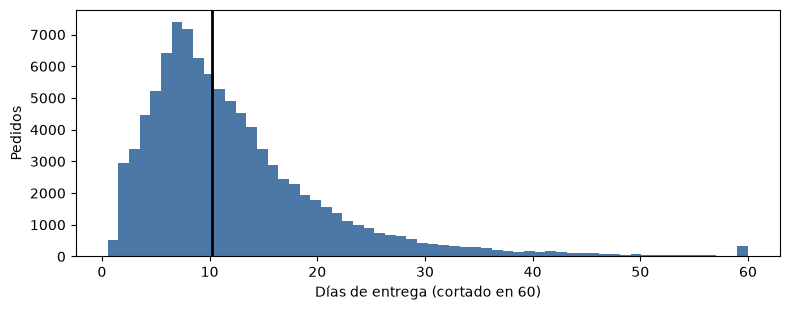

In [4]:
print(df[TARGET].describe(percentiles=[.5, .9, .99]).round(1).to_string())
print("\nvacíos en el objetivo:", df[TARGET].isna().sum(), f"({df[TARGET].isna().mean():.1%})")
print("\nestado de los pedidos sin fecha de entrega:\n", df[df[TARGET].isna()].order_status.value_counts().to_string())
print("estado 'delivered' pero sin fecha:", ((df.order_status == "delivered") & df[TARGET].isna()).sum())
print("estado distinto de 'delivered' pero con fecha:", ((df.order_status != "delivered") & df[TARGET].notna()).sum())

entregados = df[(df.order_status == "delivered") & df[TARGET].notna()].copy()
real = entregados[TARGET]
print(f"\npedidos entregados con fecha: {len(entregados):,}")
print(f"LÍNEA BASE  MAE siempre la mediana ({real.median():.1f} d): {(real - real.median()).abs().mean():.2f} días")
print(f"LÍNEA BASE  MAE con la fecha prometida hoy ({entregados.dias_prometidos.mean():.1f} d en promedio): {(real - entregados.dias_prometidos).abs().mean():.2f} días")

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(real.clip(upper=60), bins=60, color="#4C78A8")
ax.axvline(real.median(), color="black", lw=2); ax.set_xlabel("Días de entrega (cortado en 60)"); ax.set_ylabel("Pedidos")
plt.tight_layout(); plt.show()

**Hallazgo:** el objetivo no viene en los datos: se construye como entrega al cliente menos compra. 2.965 pedidos (3,0 %) no tienen fecha de entrega: 2.957 aún no se entregaron (enviados, cancelados, no disponibles...) y **8 figuran `delivered` sin fecha** (error de registro). Quedan **96.470** pedidos con objetivo en los entregados. La distribución es asimétrica con cola larga: mediana 10,2 días, promedio 12,6, p99 ≈ 46, máximo 209,6.

**Línea base (qué resultado obtiene una regla trivial):** predecir siempre la mediana (10,2 días) da un MAE de ≈ **6,1 días**. Usar la fecha prometida por la plataforma da ≈ **12,7 días**, porque promete 23,7 días en promedio.

### 2.1 ¿Qué mueve el objetivo? (mirada rápida, no es el modelo)

In [5]:
# Distancia vendedor-cliente: centroide de cada código postal en la tabla de geolocalización (que trae filas repetidas)
centroides = geo.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]].mean()
principal = (items.sort_values(["order_id", "order_item_id"]).groupby("order_id").seller_id.first().rename("seller_id"))
e = (entregados.merge(principal, left_on="order_id", right_index=True, how="left")
               .merge(sellers[["seller_id", "seller_zip_code_prefix", "seller_state"]], on="seller_id", how="left"))
a = centroides.reindex(e.customer_zip_code_prefix).to_numpy()
b = centroides.reindex(e.seller_zip_code_prefix).to_numpy()
la1, lo1, la2, lo2 = map(np.radians, [a[:, 0], a[:, 1], b[:, 0], b[:, 1]])
e["km"] = 6371 * 2 * np.arcsin(np.sqrt(np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2))
fletes = items.groupby("order_id").freight_value.sum().rename("flete")
e = e.merge(fletes, left_on="order_id", right_index=True, how="left")

print("pedidos sin coordenadas de cliente o vendedor:", e.km.isna().sum(), "| mediana de distancia (km):", round(e.km.median()))
print("\ncorrelación con los días de entrega:")
print(e[[TARGET, "km", "dias_prometidos", "flete"]].corr()[TARGET].drop(TARGET).round(2).to_string())
mismo = e.customer_state == e.seller_state
print(f"\nmismo estado vendedor-cliente: {mismo.mean():.1%} de los pedidos | mediana {e[mismo][TARGET].median():.1f} d vs {e[~mismo][TARGET].median():.1f} d si es distinto")
est = e.groupby("customer_state")[TARGET].agg(mediana="median", pedidos="size").sort_values("mediana")
print("\nestados más rápidos y más lentos (mediana de días):")
print(pd.concat([est.head(3), est.tail(3)]).round(1).to_string())

pedidos sin coordenadas de cliente o vendedor: 478 | mediana de distancia (km): 434

correlación con los días de entrega:
km                 0.39
dias_prometidos    0.38
flete              0.17

mismo estado vendedor-cliente: 36.0% de los pedidos | mediana 6.5 d vs 12.8 d si es distinto

estados más rápidos y más lentos (mediana de días):
                mediana  pedidos
customer_state                  
SP                  7.2    40494
MG                 10.3    11354
PR                 10.4     4923
AP                 24.3       67
RR                 25.0       41
AM                 25.9      145


**Hallazgo:** la **distancia** vendedor–cliente (correlación 0,39) y la **fecha prometida** (0,38) son las dos señales más fuertes; el flete aporta menos (0,17). Si vendedor y cliente están en el mismo estado, la mediana baja a 6,5 días contra 12,8. SP entrega en 7,2 días y AM en 25,9, así que el error se revisará por región.

## 3. ¿Qué tan sucios están los datos y de qué manera?

*Preguntas:* ¿hay números guardados como texto? ¿valores centinela? ¿valores imposibles? ¿vacíos? ¿duplicados? ¿datos personales?

In [6]:
# 3.1 Números/fechas como texto
print("tipo de las fechas en el CSV:", tipos_csv.unique().tolist(), "(se convirtieron a fecha al cargar)")
print("shipping_limit_date en ítems:", items.shipping_limit_date.dtype)

# 3.2 Centinelas
print("\ntipos de pago:", payments.payment_type.value_counts().to_dict())
print("pagos con 0 cuotas:", (payments.payment_installments == 0).sum())

# 3.3 Valores imposibles o extremos
print("\nproductos con peso 0 g:", (products.product_weight_g == 0).sum(), "| peso máx:", products.product_weight_g.max())
print("precio de ítem: máx", items.price.max(), "| p99", items.price.quantile(.99), "| <= 0:", (items.price <= 0).sum())
print("flete: máx", items.freight_value.max(), "| p99", items.freight_value.quantile(.99), "| = 0:", (items.freight_value == 0).sum())
print("pedidos con más de 60 días:", (real > 60).sum(), "| más de 100:", (real > 100).sum(), "| menos de 1 día:", (real < 1).sum())
fuera = geo[(geo.geolocation_lat > 6) | (geo.geolocation_lat < -34) | (geo.geolocation_lng < -74) | (geo.geolocation_lng > -33)]
print("puntos de geolocalización fuera de Brasil:", len(fuera))

# 3.5 Vacíos que significan algo
print("\nvacíos en orders:\n", orders.isna().sum()[lambda s: s > 0].to_string())
print("\nvacíos en products:\n", products.isna().sum()[lambda s: s > 0].to_string())
print("columnas con error de ortografía de origen:", [c for c in products.columns if "lenght" in c])

tipo de las fechas en el CSV: ['str'] (se convirtieron a fecha al cargar)
shipping_limit_date en ítems: str

tipos de pago: {'credit_card': 76795, 'boleto': 19784, 'voucher': 5775, 'debit_card': 1529, 'not_defined': 3}
pagos con 0 cuotas: 2

productos con peso 0 g: 4 | peso máx: 40425.0
precio de ítem: máx 6735.0 | p99 890.0 | <= 0: 0
flete: máx 409.68 | p99 84.52 | = 0: 383
pedidos con más de 60 días: 306 | más de 100: 64 | menos de 1 día: 13
puntos de geolocalización fuera de Brasil: 42

vacíos en orders:
 order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965

vacíos en products:
 product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
columnas con error de ortografía de origen: ['product_name_lenght', 'product_d

In [7]:
# 3.7 Fechas y orden temporal
print("pedidos por año:", df.order_purchase_timestamp.dt.year.value_counts().sort_index().to_dict())
por_mes = df.groupby(df.order_purchase_timestamp.dt.to_period("M")).size()
print("meses con menos de 1.000 pedidos:", {str(k): int(v) for k, v in por_mes[por_mes < 1000].items()})
print("última compra:", df.order_purchase_timestamp.max())

d = entregados
print("\nfecha de aprobación anterior a la compra:", (d.order_approved_at < d.order_purchase_timestamp).sum())
print("despacho anterior a la aprobación:", (d.order_delivered_carrier_date < d.order_approved_at).sum())
print("entrega anterior al despacho:", (d.order_delivered_customer_date < d.order_delivered_carrier_date).sum())
tarde = d.order_delivered_customer_date.dt.normalize() > d.order_estimated_delivery_date.dt.normalize()
print(f"entregados después de la fecha prometida: {tarde.sum():,} ({tarde.mean():.1%})")

# 3.6 Duplicados
print("\nduplicados exactos -> geolocalización:", geo.duplicated().sum(), "| ítems:", items.duplicated().sum(),
      "| pedidos:", orders.order_id.duplicated().sum())
print("order_id repetido -> reseñas:", reviews.order_id.duplicated().sum(), "| pagos:", payments.order_id.duplicated().sum(), "(esperable: varias por pedido)")
print("códigos postales sin coordenadas -> clientes:", (~customers.customer_zip_code_prefix.isin(geo.geolocation_zip_code_prefix)).sum(),
      "| vendedores:", (~sellers.seller_zip_code_prefix.isin(geo.geolocation_zip_code_prefix)).sum())

pedidos por año: {2016: 329, 2017: 45101, 2018: 54011}
meses con menos de 1.000 pedidos: {'2016-09': 4, '2016-10': 324, '2016-12': 1, '2017-01': 800, '2018-09': 16, '2018-10': 4}
última compra: 2018-10-17 17:30:18

fecha de aprobación anterior a la compra: 0
despacho anterior a la aprobación: 1350
entrega anterior al despacho: 23
entregados después de la fecha prometida: 6,534 (6.8%)

duplicados exactos -> geolocalización: 261831 | ítems: 0 | pedidos: 0
order_id repetido -> reseñas: 551 | pagos: 4446 (esperable: varias por pedido)
códigos postales sin coordenadas -> clientes: 278 | vendedores: 7


In [8]:
# 3.8 Categorías raras / alta cardinalidad
print("estados de clientes:", customers.customer_state.nunique(), "| ciudades:", customers.customer_city.nunique(),
      "| códigos postales:", customers.customer_zip_code_prefix.nunique())
por_vendedor = items.groupby("seller_id").size()
print("vendedores:", len(por_vendedor), "| con menos de 10 ítems:", (por_vendedor < 10).sum(),
      "| el 1 % de vendedores concentra", f"{por_vendedor.nlargest(len(por_vendedor)//100).sum() / por_vendedor.sum():.1%}", "de los ítems")
cat = products.product_category_name.value_counts()
print("categorías de producto:", len(cat), "| con menos de 100 productos:", (cat < 100).sum(),
      "| sin traducción:", (~products.product_category_name.dropna().isin(traduccion.product_category_name)).sum(), "productos")

# 3.9 Identidad y datos personales
print("\nlos ids son hash (ejemplo):", customers.customer_unique_id.iloc[0][:12], "... -> ya vienen anonimizados")

estados de clientes: 27 | ciudades: 4119 | códigos postales: 14994
vendedores: 3095 | con menos de 10 ítems: 1714 | el 1 % de vendedores concentra 26.4% de los ítems
categorías de producto: 73 | con menos de 100 productos: 38 | sin traducción: 13 productos

los ids son hash (ejemplo): 861eff4711a5 ... -> ya vienen anonimizados


**Hallazgos de calidad (con cifras):**
- **Fechas como texto** en el CSV: hay que convertirlas. Volumen estable solo de 2017-01 a 2018-08: 2016 tiene 329 pedidos y 2018-09/10 solo 20.
- **Orden raro en las fechas:** 1.350 pedidos con despacho anterior a la aprobación y 23 con entrega anterior al despacho.
- **Valores extremos:** 306 pedidos con más de 60 días y 64 con más de 100 (0,07 %); 4 productos con peso 0; 42 puntos de geolocalización fuera de Brasil; pago `not_defined` (3).
- **Vacíos con significado:** 610 productos sin categoría ni descripción (1,9 %), 2 sin peso; 160 pedidos sin fecha de aprobación.
- **Duplicados:** 261.831 filas exactas en geolocalización; reseñas y pagos repiten `order_id` (esperable).
- **Cardinalidad:** 4.119 ciudades y 14.994 códigos postales de clientes; 1.714 de 3.095 vendedores con menos de 10 ítems; el 1 % de vendedores concentra el 26 % de los ítems.
- **Coordenadas faltantes:** 278 códigos postales de clientes y 7 de vendedores no están en la tabla de geolocalización.
- **Datos personales:** los ids ya vienen anonimizados; el texto libre de las reseñas se descarta al cargar.

## 4. ¿Qué variables deberían ser estables y no lo son?

*Pregunta:* ¿qué columnas deberían ser **constantes dentro de una misma entidad**? ¿Cuántas entidades tienen más de un valor?
*(Solo aplica si una entidad aparece en varias filas: aquí, una persona con varios pedidos.)*

In [9]:
stable_candidates = ["customer_state", "customer_city", "customer_zip_code_prefix"]
cambios = {c: df.groupby("customer_unique_id")[c].nunique().gt(1).sum() for c in stable_candidates}
resumen = pd.DataFrame({"personas con más de un valor": cambios})
resumen["% de las personas"] = (resumen.iloc[:, 0] / df.customer_unique_id.nunique() * 100).round(2)
resumen["% de las que compraron 2+ veces"] = (resumen.iloc[:, 0] / (por_persona > 1).sum() * 100).round(1)
resumen

,personas con más de un valor,% de las personas,% de las que compraron 2+ veces
customer_state,39,0.04,1.3
customer_city,122,0.13,4.1
customer_zip_code_prefix,250,0.26,8.3


**Hallazgo:** la ubicación de una persona debería ser constante, y casi lo es: 39 personas tienen más de un estado y 250 más de un código postal (de 96.096 personas; ≈ 8 % de las que compraron más de una vez).

**¿Ruido o cambio real? ¿Por qué?** Probablemente **cambio real** (se mudaron entre compras) o un dato mal digitado; es un porcentaje muy pequeño. No se corrige: cada pedido conserva la ubicación con la que se compró, que es la que determinó la entrega.

## 5. ¿Hay algo que suene a fuga de información?

*Pregunta:* ¿alguna columna contiene la respuesta, o solo se conoce **después** de la decisión que quieres apoyar?
La decisión es **al comprar el pedido**. Lista las sospechosas; **no las descartes por intuición**, las mediremos en la etapa 4.

In [10]:
momento = pd.DataFrame([
    ("order_purchase_timestamp",      "al comprar",              "sí (fecha y hora de la compra)"),
    ("order_estimated_delivery_date", "al comprar",              "sí (es la fecha prometida)"),
    ("price, freight_value, shipping_limit_date", "al comprar", "sí"),
    ("datos de producto, cliente y vendedor",      "al comprar", "sí"),
    ("order_approved_at",             "horas después",           "SOSPECHOSA: se mide con y sin ella"),
    ("order_delivered_carrier_date",  "después de la decisión",  "NO (FUGA)"),
    ("order_delivered_customer_date", "es el objetivo",          "NO (FUGA: es la respuesta)"),
    ("order_status",                  "después de la decisión",  "NO (FUGA)"),
    ("review_score y review_*",       "después de la entrega",   "NO (FUGA)"),
], columns=["columna", "cuándo se conoce", "¿entra al modelo?"])
display(momento)

# Cuánto "delataría" cada una: relación con el objetivo
x = entregados.copy()
x["dias_hasta_despacho"] = (x.order_delivered_carrier_date - x.order_purchase_timestamp).dt.total_seconds() / DIA
x["dias_hasta_aprobacion"] = (x.order_approved_at - x.order_purchase_timestamp).dt.total_seconds() / DIA
x = x.merge(reviews.groupby("order_id").review_score.mean().rename("nota"), left_on="order_id", right_index=True, how="left")
print(x[[TARGET, "dias_hasta_despacho", "dias_hasta_aprobacion", "nota"]].corr()[TARGET].drop(TARGET).round(2).to_string())

,columna,cuándo se conoce,¿entra al modelo?
0,order_purchase_timestamp,al comprar,sí (fecha y hora de la compra)
1,order_estimated_delivery_date,al comprar,sí (es la fecha prometida)
2,"price, freight_value, shipping_limit_date",al comprar,sí
3,"datos de producto, cliente y vendedor",al comprar,sí
4,order_approved_at,horas después,SOSPECHOSA: se mide con y sin ella
5,order_delivered_carrier_date,después de la decisión,NO (FUGA)
6,order_delivered_customer_date,es el objetivo,NO (FUGA: es la respuesta)
7,order_status,después de la decisión,NO (FUGA)
8,review_score y review_*,después de la entrega,NO (FUGA)


dias_hasta_despacho      0.40
dias_hasta_aprobacion    0.08
nota                    -0.33


**Columnas sospechosas de fuga y por qué:**
- `order_delivered_customer_date`: es la respuesta (de ella sale el objetivo).
- `order_delivered_carrier_date`: el despacho ocurre durante la entrega y no existe al comprar. Tiene una correlación de 0,40 con el objetivo: aporta información, pero justamente la que la app no tendría.
- `order_status` y `review_*`: se conocen después de la entrega; la nota (correlación −0,33 con el objetivo) baja cuando el pedido llega tarde.
- `order_approved_at`: se conoce horas después de comprar. **No se descarta por intuición**: se mide el modelo con y sin ella en la etapa 4.
- **No son fuga:** `order_estimated_delivery_date`, precio, flete, `shipping_limit_date` y datos de producto, cliente y vendedor (se conocen al comprar).

## 6. Tabla de decisiones (entregable del EDA)

Mínimo **5 decisiones**, cada una con **cifra → acción → motivo**. Está copiada en `reports/01_eda.md`. Las funciones de `src/olistbr/data/` están por crear.

| # | Hallazgo (con cifra) | Decisión | Motivo |
|---|---|---|---|
| 1 | 2.965 de 99.441 pedidos sin fecha de entrega (8 con estado `delivered`) | Quedarse con `delivered` con fecha y construir `dias_entrega` (96.470) | Sin fecha no hay objetivo |
| 2 | 64 pedidos con más de 100 días (0,07 %); máximo 209,6 | Excluirlos del entrenamiento y reportarlos aparte | Distorsionan MAE y RMSE |
| 3 | 9.803 pedidos con varios ítems; 1.278 con varios vendedores | Una fila por pedido: sumar precio y flete, contar ítems, sumar peso y volumen | La unidad es el pedido, no el ítem |
| 4 | `order_delivered_*`, `order_status` y `review_*` son posteriores a la compra | Eliminarlas de las entradas; medir `order_approved_at` con y sin | Evitar fuga |
| 5 | 2.997 personas con varios pedidos (máx. 17) | Partición por `customer_unique_id` | Evitar la misma persona en train y test |
| 6 | Distancia vendedor–cliente: correlación 0,39; 261.831 duplicados en geolocalización; 478 pedidos sin coordenadas | Centroide por código postal, distancia en km e indicador de faltante | Es la variable más fuerte y evita la cardinalidad de la ciudad |
| 7 | 610 productos sin categoría; 2 sin peso; 4 con peso 0 | Categoría "desconocida"; peso 0 como vacío; imputar con la mediana de train | No perder pedidos ni filtrar información de test |
| 8 | 14.994 códigos postales; 1.714 vendedores con menos de 10 ítems | Usar estado y distancia; agrupar vendedores raros | Evitar memorización |
| 9 | 2016: 329 pedidos; 2018-09/10: 20 | Entrenar con 2017-01 a 2018-08 y evaluar por fecha | La app predice hacia adelante |
| 10 | Texto libre en reseñas | Descartar `review_comment_*` e ids como variables | Datos personales y fuga |

## Entregable de esta etapa

- [x] Este notebook ejecuta de principio a fin.
- [x] La tabla de decisiones tiene **al menos 5** filas con cifra y motivo (tiene 10).
- [x] `reports/01_eda.md` está actualizado.
- [x] Declaré mi **unidad de análisis** por escrito.

**Siguiente:** `03_preprocesamiento.ipynb`.